# DATA MINING, MODELING AND ANALYTICS – ASSIGNMENT 1
**Project 1: Bank Marketing Classification**
**Name:** Nabyonga Theresa
**Registration Number:** S25m19/040
**Programme:** Master of Science in Data Science and Analystics 

# PROJECT 1: BANK MARKETING CLASSIFICATION

## 1. Introduction

This project uses the Bank Marketing dataset from a Portuguese banking institution. The dataset contains customer information and details of telephone marketing campaigns. The aim is to use machine learning to predict whether a customer will subscribe to a term deposit.

## 2. Problem Formulation

The task is formulated as a binary classification problem, where the target variable `y` indicates whether a customer subscribed (yes or no). Different classification models will be compared to identify the most suitable approach and recommend a decision threshold that balances unnecessary marketing calls against missed potential subscribers.

In [6]:
# Importing the libraries needed for the analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score
)

import warnings
warnings.filterwarnings('ignore')

# Set visualisation style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option('display.max_columns', None)

print("All libraries imported successfully.")

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully.


In [7]:
# Loading the Bank Marketing dataset

df = pd.read_csv("bank-additional-full.csv", sep=";")

# Display the first five records
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [8]:
# Displaying the shape of the dataset

print("Dataset dimensions:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

Dataset dimensions: (41188, 21)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11

In [9]:
# Generating descriptive statistics

df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Checking for missing values

print("Missing values per column:")
print(df.isnull().sum())

# Check for duplicate records
print("\nNumber of duplicate records:")
print(df.duplicated().sum())

# Check target variable distribution
print("\nTarget variable distribution:")
print(df['y'].value_counts())

print("\nTarget variable percentages:")
print(df['y'].value_counts(normalize=True))

Missing values per column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Number of duplicate records:
12

Target variable distribution:
y
no     36548
yes     4640
Name: count, dtype: int64

Target variable percentages:
y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


## 3. Initial Data Exploration

The dataset contains 41,188 customer records and 21 variables, covering demographic, financial, contact and campaign-related information. Initial inspection showed no missing values, although some categorical variables contain 'unknown' entries. There are also 12 duplicate records, which will be removed during data preparation.

The target variable is imbalanced, with 88.73% of customers not subscribing and only 11.27% subscribing to a term deposit. Therefore, accuracy alone may not provide a reliable measure of model performance, making precision, recall and F1-score important evaluation metrics.

The `duration` variable will be excluded from modelling because call duration is only known after a customer has been contacted. Including it would introduce data leakage and make the model unsuitable for selecting customers before marketing calls.

In [11]:
# Identifying unknown values in categorical columns

categorical_columns = df.select_dtypes(include=['object', 'str']).columns

unknown_counts = {}

for column in categorical_columns:
    unknown_counts[column] = (df[column] == 'unknown').sum()

unknown_df = pd.DataFrame(
    list(unknown_counts.items()),
    columns=['Variable', 'Unknown_Count']
)

unknown_df = unknown_df.sort_values(
    by='Unknown_Count', ascending=False
)

unknown_df

,Variable,Unknown_Count
3,default,8597
2,education,1731
4,housing,990
5,loan,990
0,job,330
1,marital,80
6,contact,0
7,month,0
8,day_of_week,0
9,poutcome,0


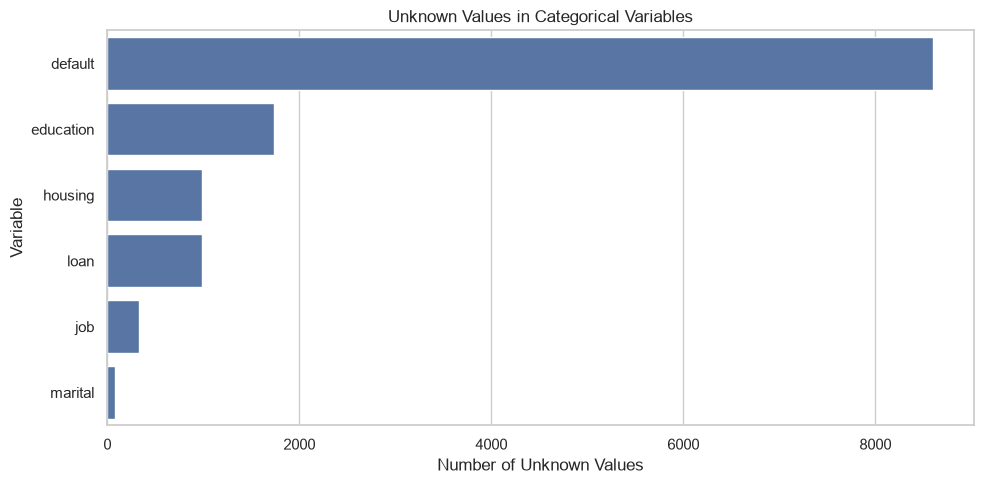

In [12]:
# We now visualise unknown values

plt.figure(figsize=(10, 5))

sns.barplot(
    data=unknown_df[unknown_df['Unknown_Count'] > 0],
    x='Unknown_Count',
    y='Variable'
)

plt.title('Unknown Values in Categorical Variables')
plt.xlabel('Number of Unknown Values')
plt.ylabel('Variable')

plt.tight_layout()
plt.show()

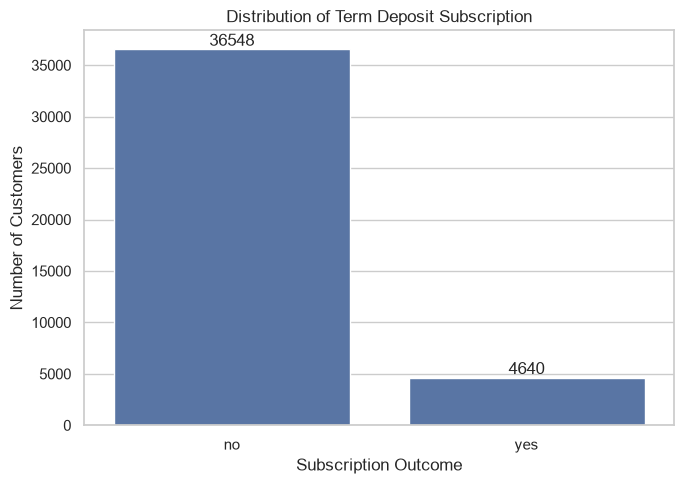

In [13]:
# Now plot target variable distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(data=df, x='y')

plt.title('Distribution of Term Deposit Subscription')
plt.xlabel('Subscription Outcome')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

### 3.1 Investigation of Unknown Values

The investigation identified unknown values in six categorical variables, with `default` having the highest count (8,597), followed by `education` (1,731). These values represent unavailable information rather than conventional missing values. They will be retained as separate categories to avoid unnecessary data loss and preserve potentially useful information.

## 4. Data Preparation

Data preparation was performed to improve data quality and ensure that the dataset was suitable for modelling. Exact duplicate records were removed, categorical variables were encoded, and numerical features were scaled where necessary. The `duration` variable was excluded to prevent data leakage because it is only available after a marketing call. The data was also divided into training and testing sets using stratified sampling to preserve the target class distribution.

In [14]:
# Creating a working copy of the dataset
data = df.copy()

# Remove exact duplicate records
data = data.drop_duplicates()

# Check the new dataset size
print("Original dataset size:", df.shape)
print("Dataset size after removing duplicates:", data.shape)
print("Remaining duplicates:", data.duplicated().sum())

Original dataset size: (41188, 21)
Dataset size after removing duplicates: (41176, 21)
Remaining duplicates: 0


In [15]:
# Separating the target variable from the input features

X = data.drop(columns=['y', 'duration'])
y = data['y'].map({'no': 0, 'yes': 1})

# Check the features and target
print("Number of input features:", X.shape[1])
print("\nTarget distribution:")
print(y.value_counts())

Number of input features: 19

Target distribution:
y
0    36537
1     4639
Name: count, dtype: int64


In [16]:
# Identifying numerical and categorical features

numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_features = X.select_dtypes(include=['object', 'str']).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


In [17]:
# Spliting the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (32940, 19)
Testing set: (8236, 19)

Training target distribution:
y
0    0.887341
1    0.112659
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.887324
1    0.112676
Name: proportion, dtype: float64


### 4.1 Data Preparation Results

After removing 12 exact duplicate records, the dataset contained 41,176 observations. The target variable was separated from 19 input features, comprising nine numerical and ten categorical variables. The `duration` variable was excluded to prevent data leakage.

The dataset was divided into training (80%) and testing (20%) sets using stratified sampling. Both sets maintained approximately the same target distribution, with 88.73% non-subscribers and 11.27% subscribers.

In [18]:
# Establishing a majority-class baseline

baseline_model = DummyClassifier(strategy='most_frequent')

# Train the baseline
baseline_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)

# Evaluate the baseline
baseline_accuracy = accuracy_score(y_test, baseline_predictions)
baseline_precision = precision_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_predictions, zero_division=0
)
baseline_f1 = f1_score(
    y_test, baseline_predictions, zero_division=0
)

print("MAJORITY-CLASS BASELINE RESULTS")
print("--------------------------------")
print(f"Accuracy:  {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall:    {baseline_recall:.4f}")
print(f"F1-score:  {baseline_f1:.4f}")

MAJORITY-CLASS BASELINE RESULTS
--------------------------------
Accuracy:  0.8873
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000


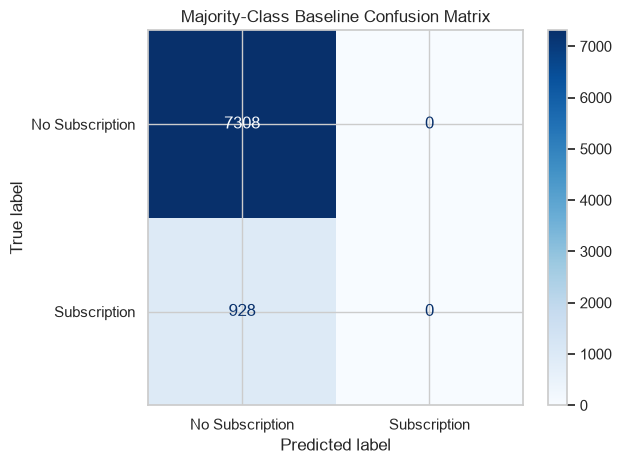

In [19]:
# Visualise baseline predictions

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_predictions,
    display_labels=['No Subscription', 'Subscription'],
    cmap='Blues'
)

plt.title('Majority-Class Baseline Confusion Matrix')
plt.tight_layout()
plt.show()

## 5. Baseline Evaluation

The majority-class baseline achieved an accuracy of 88.73%, but its precision, recall and F1-score were all zero. This is because the model predicted every customer as a non-subscriber, failing to identify any actual subscribers. Although the accuracy appears high, the model has no practical value for identifying potential customers. Therefore, more advanced classification models are required, with particular attention to their ability to identify subscribers.

In [20]:
# Preprocessing for numerical variables

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Preprocessing for categorical variables

categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# Combine both preprocessing approaches

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [22]:
# Defining the classification models

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=15,
        random_state=42
    )
}

print("Three classification models defined successfully.")

Three classification models defined successfully.


In [23]:
# Train and evaluate the classification models

results = []
trained_models = {}

for name, model in models.items():

    # Create a complete pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Generate predictions
    predictions = pipeline.predict(X_test)

    # Generate probability scores
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Calculate evaluation metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1-score': f1_score(y_test, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probabilities)
    })

    # Save trained model
    trained_models[name] = pipeline

    print(f"{name} completed successfully.")

# Display comparison
results_df = pd.DataFrame(results)

results_df.round(4)

Logistic Regression completed successfully.
Random Forest completed successfully.
HistGradientBoosting completed successfully.


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8303,0.3591,0.6455,0.4615,0.8002
1,Random Forest,0.8746,0.4456,0.4634,0.4543,0.7860
2,HistGradientBoosting,0.9010,0.6667,0.2435,0.3567,0.8131


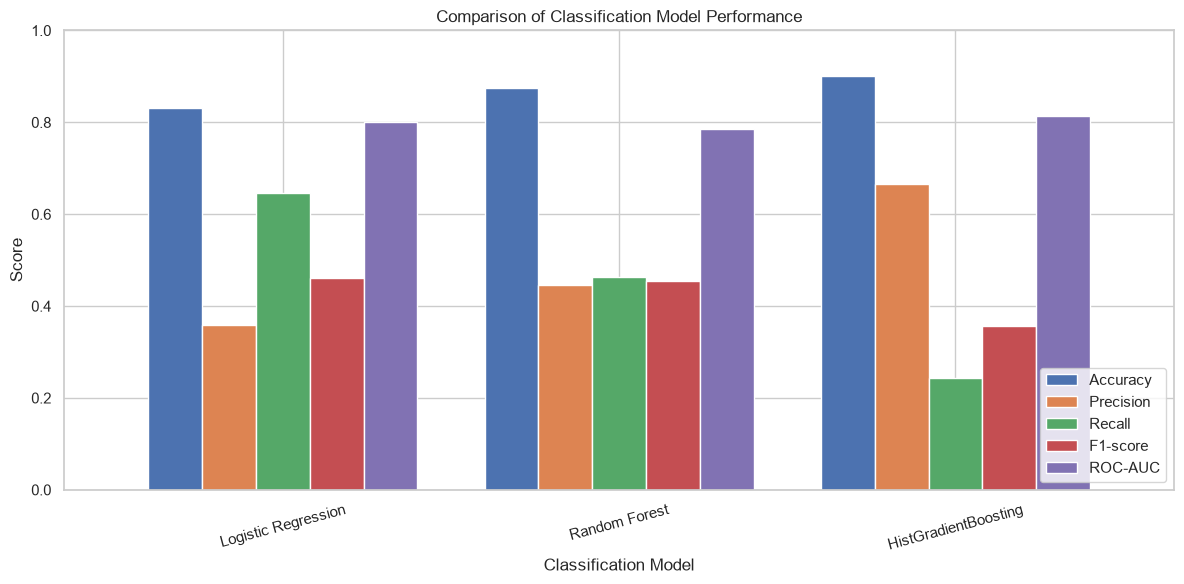

In [24]:
# Comparing model performance

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']

results_plot = results_df.set_index('Model')[metrics]

results_plot.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title('Comparison of Classification Model Performance')
plt.ylabel('Score')
plt.xlabel('Classification Model')
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 6. Model Development and Performance Comparison

Three classification models were evaluated: Logistic Regression, Random Forest and HistGradientBoosting.
 Logistic Regression achieved the highest recall (64.55%) and F1-score (46.15%), making it more suitable for identifying potential subscribers. HistGradientBoosting achieved the highest accuracy (90.10%), precision (66.67%) and ROC-AUC (0.8131), indicating better performance in ranking customers and reducing unnecessary calls at the default threshold. Random Forest achieved moderate results but did not outperform the other models on the main evaluation metrics.

Based on the results, Logistic Regression is ranked first because identifying potential subscribers is an important objective of the marketing campaign. HistGradientBoosting is ranked second due to its higher precision, while Random Forest is ranked third. However, the final model recommendation will also consider the decision threshold and the trade-off between unnecessary calls and missed subscribers.

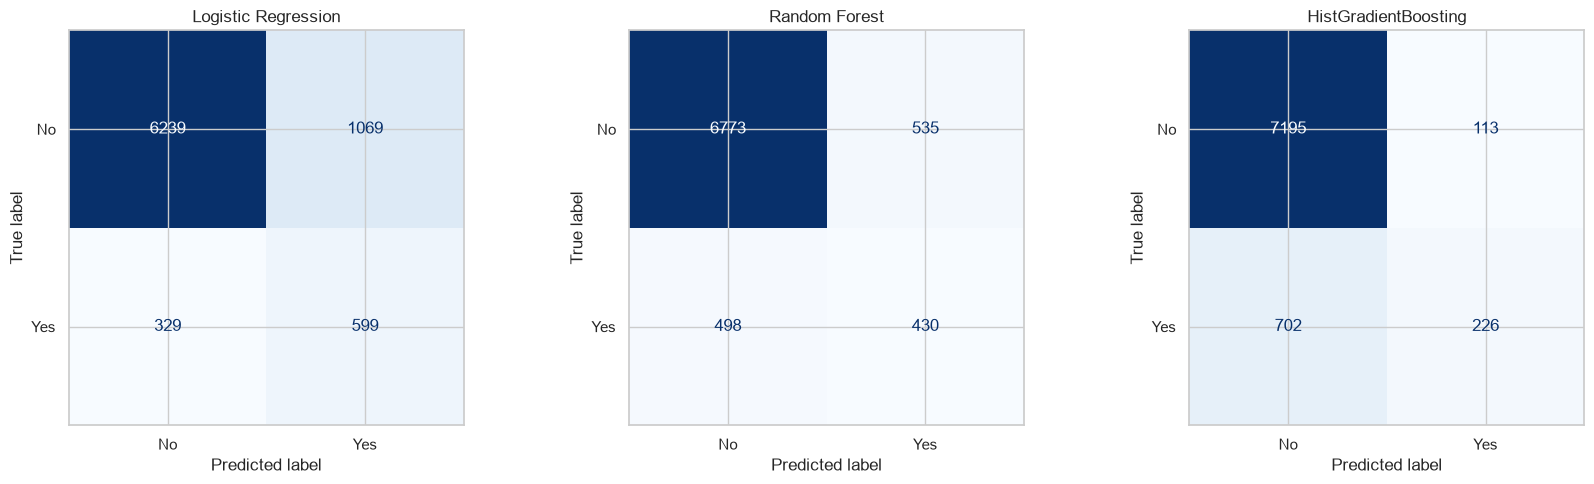

In [25]:
# Comparing confusion matrices for all three models

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, pipeline) in zip(axes, trained_models.items()):

    predictions = pipeline.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=['No', 'Yes'],
        cmap='Blues',
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [26]:
# Examining different decision thresholds for Logistic Regression

logistic_model = trained_models['Logistic Regression']

# Obtain predicted probabilities
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]

threshold_results = []

for threshold in thresholds:

    predictions = (logistic_probabilities >= threshold).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)

,Threshold,Precision,Recall,F1-score
0,0.2,0.1219,0.9698,0.2165
1,0.3,0.1663,0.8642,0.2790
2,0.4,0.2731,0.7306,0.3975
3,0.5,0.3591,0.6455,0.4615
4,0.6,0.4128,0.6272,0.4979
5,0.7,0.4744,0.5183,0.4954


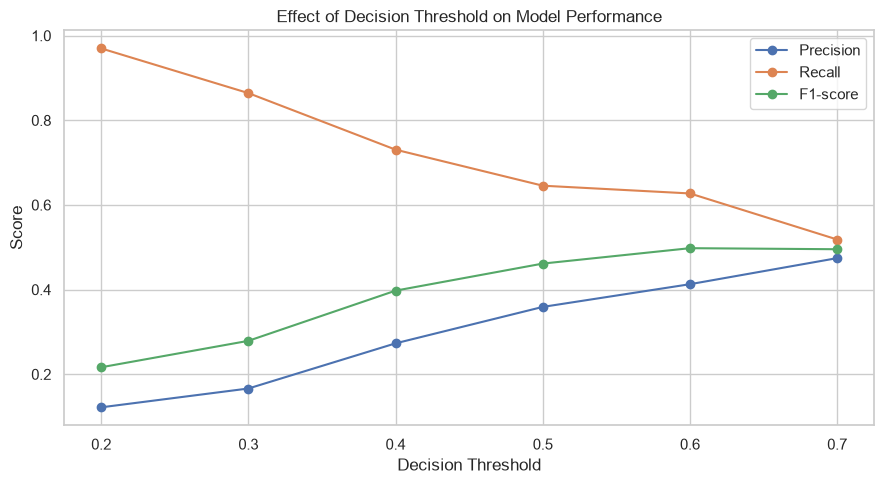

In [27]:
# Plot precision and recall at different thresholds

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1-score'],
    marker='o',
    label='F1-score'
)

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Effect of Decision Threshold on Model Performance')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 7. Decision Threshold Analysis

Different decision thresholds were evaluated using Logistic Regression to examine the trade-off between precision and recall. Lower thresholds increased recall but resulted in more false-positive predictions, potentially leading to unnecessary marketing calls. Higher thresholds improved precision but increased the number of missed subscribers.

A threshold of 0.60 achieved the highest F1-score of 49.79%, with precision of 41.28% and recall of 62.72%. Therefore, it is a promising threshold because it provides a reasonable balance between identifying potential subscribers and reducing unnecessary calls. However, the final threshold should be selected using validation data and evaluated on an independent test set.

In [28]:
# Spliting training data into training and validation sets

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train Logistic Regression on the new training set

final_logistic = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

final_logistic.fit(X_train_new, y_train_new)

# Obtain validation probabilities
val_probabilities = final_logistic.predict_proba(X_val)[:, 1]

# Compare thresholds
thresholds = [0.40, 0.50, 0.60, 0.70]

validation_results = []

for threshold in thresholds:

    predictions = (val_probabilities >= threshold).astype(int)

    validation_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_val, predictions),
        'Recall': recall_score(y_val, predictions),
        'F1-score': f1_score(y_val, predictions)
    })

validation_df = pd.DataFrame(validation_results)

validation_df.round(4)

,Threshold,Precision,Recall,F1-score
0,0.4,0.2740,0.7345,0.3991
1,0.5,0.3735,0.6348,0.4703
2,0.6,0.4121,0.6038,0.4899
3,0.7,0.4684,0.5094,0.4881


In [29]:
# Evaluate the selected threshold on the test set

selected_threshold = 0.60  # Update using validation results

test_probabilities = final_logistic.predict_proba(X_test)[:, 1]

final_predictions = (
    test_probabilities >= selected_threshold
).astype(int)

print("FINAL TEST RESULTS")
print("------------------")
print("Threshold:", selected_threshold)
print("Precision:", round(precision_score(y_test, final_predictions), 4))
print("Recall:", round(recall_score(y_test, final_predictions), 4))
print("F1-score:", round(f1_score(y_test, final_predictions), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

FINAL TEST RESULTS
------------------
Threshold: 0.6
Precision: 0.4177
Recall: 0.6239
F1-score: 0.5004

Confusion Matrix:
[[6501  807]
 [ 349  579]]


## 8. Conclusion and Recommendation

The study evaluated three machine learning models for predicting term-deposit subscriptions. Logistic Regression achieved the highest recall (64.55%) and F1-score (46.15%) at the default threshold, while HistGradientBoosting achieved the highest accuracy, precision and ROC-AUC.

Validation results identified 0.60 as the preferred Logistic Regression threshold, producing a test precision of 41.77%, recall of 62.39% and F1-score of 50.04%.

Overall, Logistic Regression with a 0.60 threshold is recommended because it provides a reasonable balance between identifying potential subscribers and reducing unnecessary marketing calls. However, some subscribers may still be missed, and some unnecessary calls may occur.